# Reto avanzado 1 — Comparativa de algoritmos de clustering

Objetivo: comparar K-Means (Reto 3) con otros algoritmos de clustering y decidir cuál es el más adecuado para segmentar a los clientes.

Pasos, en el orden del enunciado:

1. Entrenar los algoritmos alternativos con **el mismo k y los mismos datos preparados**: `X_model.csv` (19 features escaladas) y k = 5.
2. Comparar los Silhouette Scores de todos los algoritmos.
3. Analizar si los segmentos cambian significativamente entre algoritmos.
4. Gráfico comparativo de rendimiento.
5. Conclusión razonada sobre el algoritmo más adecuado.

Algoritmos comparados:

| Algoritmo | Tipo | ¿Recibe k? |
|---|---|---|
| **K-Means** (referencia, Reto 3) | Particional, basado en centroides | Sí |
| **Gaussian Mixture Model (GMM)** | Probabilístico (*soft clustering*): cada cliente tiene una probabilidad de pertenecer a cada cluster | Sí (nº de componentes) |
| **DBSCAN** | Basado en densidad: agrupa zonas densas y marca como ruido los puntos aislados | **No**: el nº de clusters sale de `eps` y `min_samples` |

> Requisito: ejecutar antes `notebooks-básico/02_feature_engineering.ipynb` y `03_kmeans.ipynb`, que generan `data/processed/`.

## Resumen

**Qué se hizo:** comparación del K-Means del Reto 3 con GMM y DBSCAN, con los mismos datos (`X_model.csv`) y k = 5.

**Resultados clave**
- **Silhouette:** K-Means 0,137 · GMM 0,090 · DBSCAN 0,185, pero con solo 2 clusters, por lo que no es comparable (sección 4).
- **GMM** fusiona segmentos (ARI 0,39 frente a K-Means) y crea un cluster residual del 2 % (sección 2).
- **DBSCAN** no admite k: con ningún `eps` encuentra 5 grupos (el gráfico de k-distancias no tiene codo: los datos son un continuo); con `eps = 2,5` solo separa a los Clientes Perdidos (sección 3).
- **Clientes Perdidos** es el único segmento que detectan los tres algoritmos.

**Conclusión:** K-Means es el más adecuado: mejor Silhouette con k = 5, segmentos equilibrados e interpretables, resultado estable y capaz de asignar clientes nuevos.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import DBSCAN
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_colwidth", None)

PROCESSED = next(p for p in (Path("data/processed"), Path("../data/processed")) if p.exists())

X = pd.read_csv(PROCESSED / "X_model.csv", index_col="client_id")
X_np = X.to_numpy()
K = 5

# K-Means labels from the final model of the Reto 3
kmeans_labels = pd.read_csv(PROCESSED / "clusters.csv", index_col="client_id")["cluster"].loc[X.index].to_numpy()

# Segment names: same rules as notebooks-básico/04_segmentos.ipynb
clients = pd.read_csv(PROCESSED / "client_features.csv", index_col="client_id").loc[X.index]
means = clients.groupby(kmeans_labels)[["n_current_vehicles", "consent_level", "pct_plugin", "months_as_mb_customer"]].mean()
names = {}
names[means["n_current_vehicles"].idxmin()] = "Clientes Perdidos"
names[means["consent_level"].drop(list(names)).idxmin()] = "Clientes Silenciosos"
names[means["pct_plugin"].drop(list(names)).idxmax()] = "Pioneros Eléctricos"
names[means["months_as_mb_customer"].drop(list(names)).idxmax()] = "Fieles Acomodados"
names[means.index.difference(list(names))[0]] = "Candidatos a Renovación"
ORDER = ["Fieles Acomodados", "Candidatos a Renovación", "Pioneros Eléctricos", "Clientes Silenciosos", "Clientes Perdidos"]
segment = pd.Categorical(pd.Series(kmeans_labels).map(names), categories=ORDER, ordered=True)

# Common sample: Silhouette is O(n²) and DBSCAN is costly on 173k points
SAMPLE = np.random.default_rng(42).choice(len(X), 20_000, replace=False)

print(f"Matriz: {X.shape[0]:,} clientes × {X.shape[1]} features | k = {K} | muestra común: {len(SAMPLE):,}")

Matriz: 173,454 clientes × 19 features | k = 5 | muestra común: 20,000


**Muestra común.** El Silhouette necesita las distancias entre todos los pares de puntos y DBSCAN busca vecinos de cada punto: con 173.454 clientes no es viable. Todas las métricas se calculan sobre **la misma muestra aleatoria de 20.000 clientes**, para que la comparación sea justa. Por eso el Silhouette de K-Means aquí (0,137, una muestra) difiere ligeramente del Reto 3 (0,136, media de 5 muestras de 20.000): es solo la variación por muestreo. K-Means y GMM se entrenan con **todos** los clientes; DBSCAN, sobre la muestra.

## 1. K-Means (referencia)

Se reutilizan las asignaciones del modelo final del Reto 3 (k = 5, `k-means++`, 10 inicializaciones, la mejor de 5 semillas).

In [2]:
def summarize(labels, name):
    labels = np.asarray(labels)
    valid = labels != -1
    sizes = np.bincount(labels[valid]) / valid.sum() * 100
    return {
        "algoritmo": name,
        "clusters": len(np.unique(labels[valid])),
        "ruido_%": (~valid).mean() * 100,
        "silhouette": silhouette_score(X_np[SAMPLE][valid[SAMPLE]], labels[SAMPLE][valid[SAMPLE]]) if len(np.unique(labels[valid])) > 1 else np.nan,
        "cluster_min_%": sizes.min(),
        "cluster_max_%": sizes.max(),
    }

results = [summarize(kmeans_labels, "K-Means")]
pd.DataFrame(results).set_index("algoritmo")

,clusters,ruido_%,silhouette,cluster_min_%,cluster_max_%
algoritmo,,,,,
K-Means,5,0.000,0.137,10.124,33.657


## 2. Gaussian Mixture Model (GMM)

GMM supone que los datos son una mezcla de k distribuciones normales y estima, para cada cliente, la **probabilidad** de pertenecer a cada una. A diferencia de K-Means, cada cluster puede tener forma elíptica y tamaño propio (`covariance_type="full"`). Se usa el mismo k = 5 y se asigna cada cliente al componente más probable.

In [3]:
gmm = GaussianMixture(n_components=K, covariance_type="full", n_init=3, random_state=42).fit(X_np)
gmm_labels = gmm.predict(X_np)
gmm_max_prob = gmm.predict_proba(X_np).max(axis=1)

print(f"Convergencia: {gmm.converged_} en {gmm.n_iter_} iteraciones")
print(f"Clientes con probabilidad máxima < 0,6 (asignación dudosa): {(gmm_max_prob < 0.6).mean():.1%}")

results.append(summarize(gmm_labels, "GMM"))
pd.DataFrame(results).set_index("algoritmo")

Convergencia: True en 16 iteraciones
Clientes con probabilidad máxima < 0,6 (asignación dudosa): 0.0%


,clusters,ruido_%,silhouette,cluster_min_%,cluster_max_%
algoritmo,,,,,
K-Means,5,0.000,0.137,10.124,33.657
GMM,5,0.000,0.090,1.881,50.094


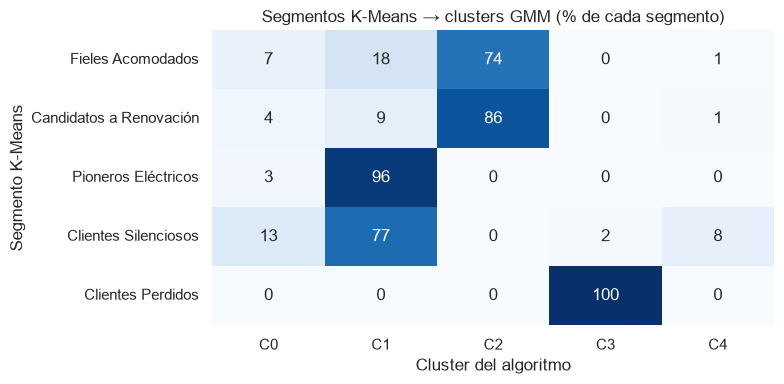

ARI K-Means vs GMM: 0.386


In [4]:
def crosstab(labels, title, ax):
    labels = np.asarray(labels)
    table = pd.crosstab(segment, labels, normalize="index") * 100
    table.columns = ["ruido" if c == -1 else f"C{c}" for c in table.columns]
    sns.heatmap(table, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, cbar=False, ax=ax)
    ax.set(title=title, xlabel="Cluster del algoritmo", ylabel="Segmento K-Means")

fig, ax = plt.subplots(figsize=(8, 4))
crosstab(gmm_labels, "Segmentos K-Means → clusters GMM (% de cada segmento)", ax)
plt.tight_layout()
plt.show()

print(f"ARI K-Means vs GMM: {adjusted_rand_score(kmeans_labels, gmm_labels):.3f}")

**Interpretación**

- GMM **no reproduce** la segmentación de K-Means (ARI ≈ 0,39; 1 = idénticas):
  - Junta a la mayoría de **Fieles Acomodados** y **Candidatos a Renovación** en un único cluster de la mitad de los clientes.
  - Junta a **Pioneros Eléctricos** y a la mayoría de **Clientes Silenciosos** en otro.
  - Solo conserva intacto el segmento de **Clientes Perdidos**.
  - Crea un cluster muy pequeño (~2 % de los clientes).
- Su Silhouette es **menor** que el de K-Means (≈ 0,09 frente a ≈ 0,14): los clusters de GMM están peor separados en el espacio de las features.
- Prácticamente ningún cliente tiene una probabilidad máxima inferior a 0,6: GMM asigna con mucha seguridad aunque los grupos se solapen. Es un efecto conocido con covarianzas completas en datos con muchas variables binarias o con pocos valores (one-hot, `consent_level`): algunos componentes se ajustan a combinaciones concretas de esas variables en lugar de a perfiles de cliente.

## 3. DBSCAN

DBSCAN agrupa los puntos que tienen al menos `min_samples` vecinos a distancia ≤ `eps` y marca como **ruido** (−1) los que quedan aislados. No recibe k: el número de clusters depende de la densidad de los datos.

**Elección de parámetros:**

- `min_samples = 2 × nº de features = 38`, la regla habitual.
- `eps`: se elige con el **gráfico de k-distancias** (distancia de cada punto a su vecino nº 38, ordenada). El codo de la curva marca la distancia a partir de la cual los puntos dejan de estar en zonas densas.

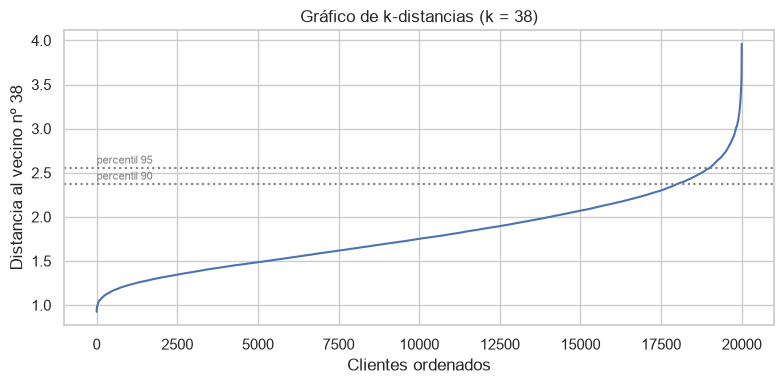

,p50,p75,p90,p95,p99
k-distancia,1.751,2.070,2.372,2.553,2.974


In [5]:
MIN_SAMPLES = 2 * X.shape[1]
X_sample = X_np[SAMPLE]

k_dist = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X_sample).kneighbors(X_sample)[0][:, -1])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(k_dist)
for q in (90, 95):
    ax.axhline(np.percentile(k_dist, q), linestyle=":", color="gray")
    ax.text(0, np.percentile(k_dist, q) + 0.05, f"percentil {q}", fontsize=8, color="gray")
ax.set(title=f"Gráfico de k-distancias (k = {MIN_SAMPLES})", xlabel="Clientes ordenados", ylabel=f"Distancia al vecino nº {MIN_SAMPLES}")
plt.tight_layout()
plt.show()

pd.Series(np.percentile(k_dist, [50, 75, 90, 95, 99]), index=["p50", "p75", "p90", "p95", "p99"], name="k-distancia").to_frame().T

La curva sube de forma **gradual**, sin un codo marcado: no hay una distancia que separe claramente zonas densas de zonas vacías. Es la misma señal que el Silhouette bajo del Reto 3: los clientes forman un continuo. Para ver el efecto de `eps`, se prueba un rango alrededor de los percentiles de la curva:

In [6]:
rows = []
for eps in [1.5, 2.0, 2.5, 3.0, 3.5]:
    labels = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X_sample)
    valid = labels != -1
    n_clusters = len(np.unique(labels[valid]))
    rows.append({
        "eps": eps,
        "clusters": n_clusters,
        "ruido_%": (~valid).mean() * 100,
        "cluster_mayor_%": np.bincount(labels[valid]).max() / valid.sum() * 100 if valid.any() else np.nan,
        "silhouette (sin ruido)": silhouette_score(X_sample[valid], labels[valid]) if n_clusters > 1 else np.nan,
    })
pd.DataFrame(rows).set_index("eps")

,clusters,ruido_%,cluster_mayor_%,silhouette (sin ruido)
eps,,,,
1.500,4,45.430,81.748,0.053
2.000,2,8.155,90.968,0.182
2.500,2,0.445,89.780,0.185
3.000,1,0.005,100.000,NaN
3.500,1,0.000,100.000,NaN


**Interpretación**

- **Ningún valor de `eps` produce 5 clusters**: con `eps` pequeño (1,5) marca como ruido a casi la mitad de los clientes (45 %) y deja un cluster con ~82 % del resto; con `eps` ≥ 3 une a todos en un único grupo. En la zona del codo (`eps` ≈ 2,5, entre los percentiles 90 y 95) encuentra **2 clusters**, uno con ~90 % de los clientes, y apenas ruido.
- El Silhouette de DBSCAN puede salir **más alto** que el de K-Means, pero no es comparable: mide la separación de 2 grupos muy desiguales (y, con `eps` bajo, después de descartar como ruido a gran parte de los clientes).
- Se elige `eps = 2,5` (zona del codo, ruido < 2 %) para la comparativa:

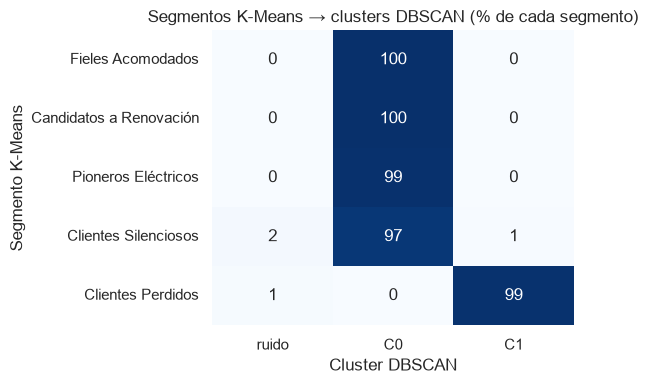

ARI K-Means vs DBSCAN (muestra): 0.137


In [7]:
DBSCAN_EPS = 2.5
dbscan_sample = DBSCAN(eps=DBSCAN_EPS, min_samples=MIN_SAMPLES).fit_predict(X_sample)

# DBSCAN only labels the sample: compare against K-Means on the same clients
dbscan_labels = np.full(len(X), -2)
dbscan_labels[SAMPLE] = dbscan_sample
valid = dbscan_sample != -1
results.append({
    "algoritmo": f"DBSCAN (eps={DBSCAN_EPS})",
    "clusters": len(np.unique(dbscan_sample[valid])),
    "ruido_%": (~valid).mean() * 100,
    "silhouette": silhouette_score(X_sample[valid], dbscan_sample[valid]),
    "cluster_min_%": np.bincount(dbscan_sample[valid]).min() / valid.sum() * 100,
    "cluster_max_%": np.bincount(dbscan_sample[valid]).max() / valid.sum() * 100,
})

table = pd.crosstab(segment[SAMPLE], dbscan_sample, normalize="index") * 100
table.columns = ["ruido" if c == -1 else f"C{c}" for c in table.columns]
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(table, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, cbar=False, ax=ax)
ax.set(title="Segmentos K-Means → clusters DBSCAN (% de cada segmento)", xlabel="Cluster DBSCAN", ylabel="Segmento K-Means")
plt.tight_layout()
plt.show()

print(f"ARI K-Means vs DBSCAN (muestra): {adjusted_rand_score(kmeans_labels[SAMPLE], dbscan_sample):.3f}")

**Interpretación**

- El cluster pequeño de DBSCAN coincide con los **Clientes Perdidos**, el segmento más diferente (sin vehículos actuales). El resto de segmentos queda unido en un único gran cluster.
- DBSCAN solo detecta la frontera más marcada de los datos; para separar los demás perfiles necesitaría zonas de baja densidad entre ellos, y no las hay.

## 4. Comparativa de rendimiento

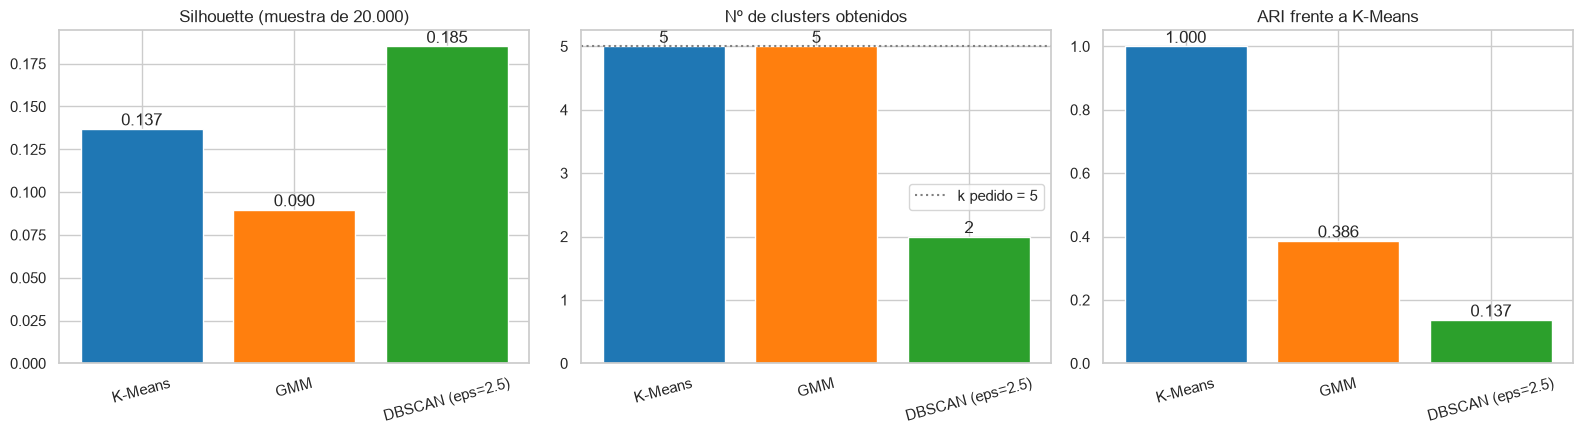

,clusters,ruido_%,silhouette,cluster_min_%,cluster_max_%,ARI vs K-Means
algoritmo,,,,,,
K-Means,5,0.000,0.137,10.124,33.657,1.000
GMM,5,0.000,0.090,1.881,50.094,0.386
DBSCAN (eps=2.5),2,0.445,0.185,10.220,89.780,0.137


In [8]:
comparison = pd.DataFrame(results).set_index("algoritmo")
comparison["ARI vs K-Means"] = [
    1.0,
    adjusted_rand_score(kmeans_labels, gmm_labels),
    adjusted_rand_score(kmeans_labels[SAMPLE], dbscan_sample),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
colors = sns.color_palette("tab10", len(comparison))
for ax, col, title in zip(axes, ["silhouette", "clusters", "ARI vs K-Means"],
                          ["Silhouette (muestra de 20.000)", "Nº de clusters obtenidos", "ARI frente a K-Means"]):
    bars = ax.bar(comparison.index, comparison[col], color=colors)
    ax.bar_label(bars, fmt="%.3f" if col != "clusters" else "%d")
    ax.set(title=title)
    ax.tick_params(axis="x", rotation=15)
axes[1].axhline(K, color="gray", linestyle=":", label=f"k pedido = {K}")
axes[1].legend()
plt.tight_layout()
plt.show()

comparison

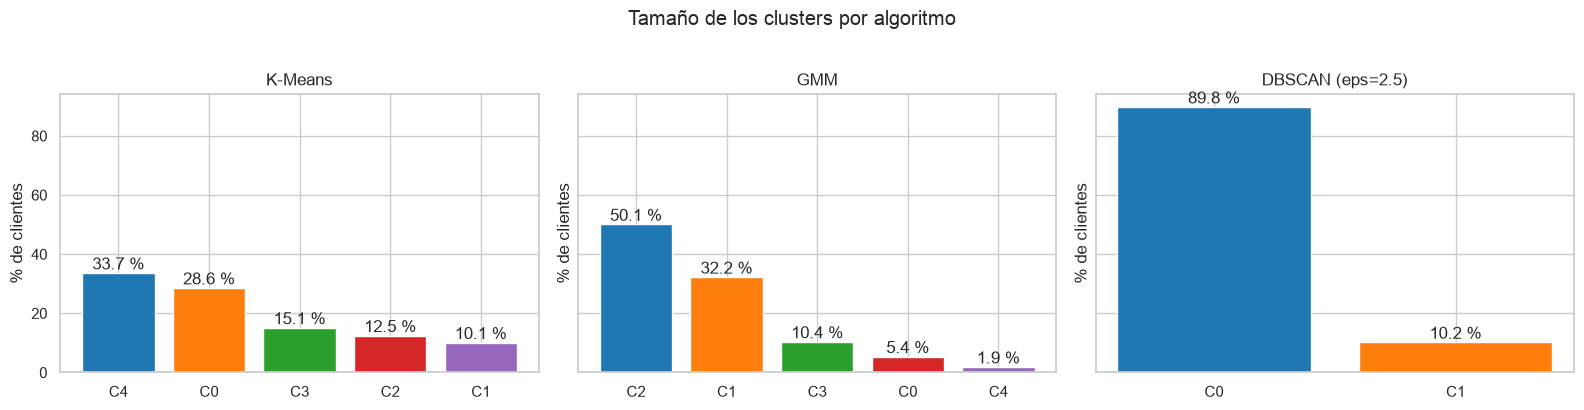

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (name, labels) in zip(axes, [("K-Means", kmeans_labels), ("GMM", gmm_labels), (f"DBSCAN (eps={DBSCAN_EPS})", dbscan_sample)]):
    labels = np.asarray(labels)
    labels = labels[labels != -1]
    sizes = pd.Series(labels).value_counts(normalize=True).sort_values(ascending=False) * 100
    bars = ax.bar([f"C{c}" for c in sizes.index], sizes.values, color=sns.color_palette("tab10", len(sizes)))
    ax.bar_label(bars, fmt="%.1f %%")
    ax.set(title=name, ylabel="% de clientes")
plt.suptitle("Tamaño de los clusters por algoritmo", y=1.02)
plt.tight_layout()
plt.show()

**Interpretación**

| Criterio | K-Means | GMM | DBSCAN |
|---|---|---|---|
| Respeta k = 5 | Sí | Sí | **No** (2 clusters) |
| Silhouette | **El más alto con 5 clusters (≈ 0,14)** | Menor (≈ 0,09) | Mayor, pero con solo 2 grupos: no comparable |
| ¿Mismos segmentos que K-Means? | — | **No** (ARI ≈ 0,39): fusiona segmentos | **No**: solo separa a los Clientes Perdidos |
| Tamaños | Equilibrados (10–34 %) | Desequilibrados (2–50 %) | ~90 % / ~10 % |
| Asignar clientes nuevos | Sí (centroide más cercano) | Sí (`predict`) | No directamente |

- **Los segmentos cambian significativamente entre algoritmos.** Lo que se mantiene en los tres es el segmento de **Clientes Perdidos**, el más diferenciado: es un perfil robusto, que cualquier método detecta.

## Conclusión: ¿qué algoritmo es el más adecuado?

**K-Means** es el algoritmo más adecuado para este problema:

1. **Mejor Silhouette con k = 5** (≈ 0,14 frente a ≈ 0,09 de GMM).
2. **Segmentos equilibrados e interpretables**: los 5 segmentos del Reto 4 tienen tamaño suficiente (10–34 %) para campañas diferenciadas y un perfil de negocio claro. GMM fusiona segmentos con perfiles distintos y crea un cluster residual; DBSCAN solo distingue 2 grupos.
3. **Reproducible y estable**: el mismo resultado con 5 semillas (ARI ≥ 0,99, Reto 3).
4. **Operativo**: un cliente nuevo se asigna al segmento del centroide más cercano, algo que DBSCAN no permite directamente.

DBSCAN y GMM no son malos algoritmos, pero sus supuestos no encajan con estos datos: DBSCAN necesita zonas de baja densidad entre grupos y GMM, distribuciones aproximadamente normales, mientras que aquí los clientes forman un **continuo** con muchas variables binarias. Para partir ese continuo en perfiles útiles para negocio, K-Means es la opción más sólida.